![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Aplicación resuelta 3 · Reconocedor de símbolos

**Propósito:** Distinguir cuadrados y círculos negros mediante sus contornos.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Situación práctica
Una cámara observa símbolos impresos en una etiqueta. Nuestro sistema debe clasificarlos en **cuadrados** y **círculos**.

En esta práctica usamos geometría en lugar de un modelo entrenado para comprender el procedimiento.

**Pasos:** leer → binarizar → encontrar objetos → contar vértices → asignar nombre.

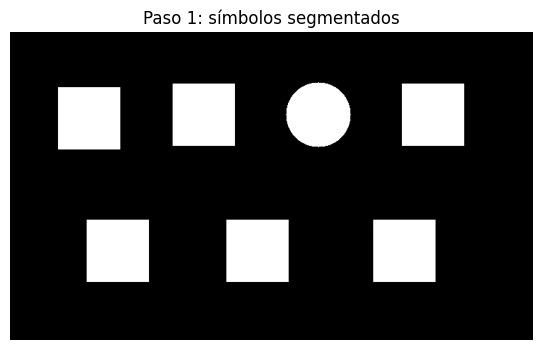

In [2]:
imagen = cv2.imread(str(RECURSOS / 'patrones.png'))
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
_, mascara = cv2.threshold(gris, 120, 255, cv2.THRESH_BINARY_INV)
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
mostrar(mascara, 'Paso 1: símbolos segmentados', gris=True)

Cuadrados: 6 | Círculos: 1


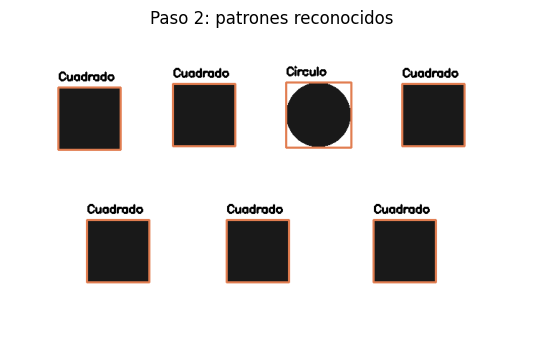

True

In [3]:
resultado = imagen.copy()
cuadrados = 0
circulos = 0
for c in contornos:
    if cv2.contourArea(c) < 400:
        continue
    perimetro = cv2.arcLength(c, True)
    aproximado = cv2.approxPolyDP(c, 0.03 * perimetro, True)
    if len(aproximado) == 4:
        nombre = 'Cuadrado'
        cuadrados += 1
    else:
        nombre = 'Circulo'
        circulos += 1
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(resultado, (x, y), (x+w, y+h), (80, 125, 225), 2)
    cv2.putText(resultado, nombre, (x, max(25, y-10)), cv2.FONT_HERSHEY_SIMPLEX,.53,(0,0,0),2)
print(f'Cuadrados: {cuadrados} | Círculos: {circulos}')
assert (cuadrados, circulos) == (6, 1), 'Revisar la clasificación geométrica.'
mostrar(resultado, 'Paso 2: patrones reconocidos')
cv2.imwrite(str(SALIDAS / 'patrones_reconocidos.png'), resultado)

**Explicación:** `approxPolyDP` reemplaza un contorno muy detallado por un polígono aproximado. Si aparecen cuatro esquinas, lo llamamos cuadrado en este ejemplo. En producción habría que comprobar además la relación ancho/alto, la rotación y otras formas.

**Reto final:** ¿cómo extenderías el programa para reconocer también triángulos? Pista: tres vértices.

**Cierre:** detección encuentra *dónde*, segmentación marca *qué píxeles* y reconocimiento interpreta *qué forma es*.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Cómo detectar triángulos?** Con `cv2.approxPolyDP`: si un contorno tiene **3 vértices**, clasificarlo como triángulo. Prueba: **1 triángulo**, **6 cuadriláteros** y **1 círculo aproximado**.

## Ejecución del reto del estudiante (actividad resuelta)

Conteo de patrones: {'triangulo': 1, 'cuadrilatero': 6, 'circulo_aproximado': 1}


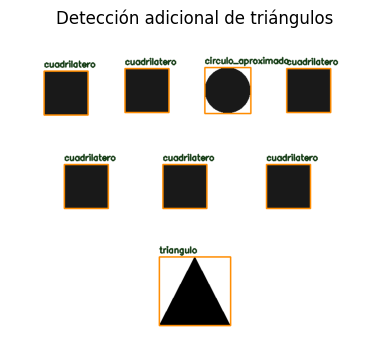

In [4]:
# Actividad del estudiante: extender el reconocedor a TRIÁNGULOS.
original=cv2.imread(str(RECURSOS/'patrones.png'))
alto,ancho=original.shape[:2]
imagen_nueva=np.full((alto+180,ancho,3),255,dtype=np.uint8)
imagen_nueva[:alto,:]=original
triangle=np.array([[ancho//2,alto+15],[ancho//2-70,alto+150],[ancho//2+70,alto+150]],dtype=np.int32)
cv2.fillPoly(imagen_nueva,[triangle],(0,0,0))
gris=cv2.cvtColor(imagen_nueva,cv2.COLOR_BGR2GRAY)
_,mascara=cv2.threshold(gris,120,255,cv2.THRESH_BINARY_INV)
contornos,_=cv2.findContours(mascara,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
resultado=imagen_nueva.copy();tipos={'triangulo':0,'cuadrilatero':0,'circulo_aproximado':0}
for c in contornos:
    if cv2.contourArea(c)<400:continue
    aproximado=cv2.approxPolyDP(c,0.03*cv2.arcLength(c,True),True)
    lados=len(aproximado)
    nombre='triangulo' if lados==3 else 'cuadrilatero' if lados==4 else 'circulo_aproximado'
    tipos[nombre]+=1
    x,y,w,h=cv2.boundingRect(c)
    cv2.rectangle(resultado,(x,y),(x+w,y+h),(0,140,255),2)
    cv2.putText(resultado,nombre,(x,max(18,y-8)),cv2.FONT_HERSHEY_SIMPLEX,0.55,(20,60,20),2)
print('Conteo de patrones:',tipos)
cv2.imwrite(str(SALIDAS/'07_patrones_antes.png'),imagen_nueva)
cv2.imwrite(str(SALIDAS/'07_patrones_despues.png'),resultado)
mostrar(resultado,'Detección adicional de triángulos')

### Conclusión y evaluación

Tres vértices aproximados corresponden a triángulos, cuatro a cuadriláteros y otros contornos se etiquetan como circulares solo de forma aproximada. El nuevo triángulo se dibuja sobre una copia, preservando `patrones.png` original.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.